# Check Peaks Results Summary

Summarise `data/zooniverse/check_peaks_results.csv`, including agreement/vote count distributions and requested plots.

In [1]:
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
CSV_PATH = Path("data/zooniverse/check_peaks_results.csv")
AGREEMENT_COL = "data.agreement"
NUM_VOTES_COL = "data.num_votes"
MOST_LIKELY_COL = "data.most_likely"

In [3]:
results = pd.read_csv(CSV_PATH)

results[AGREEMENT_COL] = pd.to_numeric(results[AGREEMENT_COL], errors="coerce")
results[NUM_VOTES_COL] = pd.to_numeric(results[NUM_VOTES_COL], errors="coerce")

display(results.head())

,id,reducer_key,workflow_id,subject_id,created_at,updated_at,subgroup,lock_version,reducible_id,reducible_type,data.agreement,data.num_votes,data.most_likely
0,115479595,consensus,31708,119517112,2026-04-21 10:26:21 UTC,2026-05-13 20:28:49 UTC,_default,2,31708,Workflow,0.666667,2,0.0
1,115479598,consensus,31708,119628021,2026-04-21 10:26:25 UTC,2026-04-21 20:30:41 UTC,_default,1,31708,Workflow,0.500000,1,NaN
2,115479604,consensus,31708,119617362,2026-04-21 10:26:29 UTC,2026-05-13 13:33:57 UTC,_default,2,31708,Workflow,0.666667,2,0.0
3,115479620,consensus,31708,119537811,2026-04-21 10:26:37 UTC,2026-04-24 22:57:02 UTC,_default,1,31708,Workflow,0.500000,1,1.0
4,115479622,consensus,31708,119591393,2026-04-21 10:26:43 UTC,2026-05-04 14:55:12 UTC,_default,3,31708,Workflow,0.500000,2,1.0


## Summary

In [4]:
summary = pd.Series(
    {
        "rows": len(results),
        "subjects": results["subject_id"].nunique() if "subject_id" in results else pd.NA,
        "agreement_min": results[AGREEMENT_COL].min(),
        "agreement_mean": results[AGREEMENT_COL].mean(),
        "agreement_median": results[AGREEMENT_COL].median(),
        "agreement_max": results[AGREEMENT_COL].max(),
        "num_votes_min": results[NUM_VOTES_COL].min(),
        "num_votes_mean": results[NUM_VOTES_COL].mean(),
        "num_votes_median": results[NUM_VOTES_COL].median(),
        "num_votes_max": results[NUM_VOTES_COL].max(),
        "missing_agreement": results[AGREEMENT_COL].isna().sum(),
        "missing_num_votes": results[NUM_VOTES_COL].isna().sum(),
    },
    name="value",
)

display(summary.to_frame())
display(results[[AGREEMENT_COL, NUM_VOTES_COL]].describe().T)

,value
rows,85457.000000
subjects,85457.000000
agreement_min,0.200000
agreement_mean,0.810408
agreement_median,1.000000
agreement_max,1.000000
num_votes_min,1.000000
num_votes_mean,1.613981
num_votes_median,1.000000
num_votes_max,6.000000


,count,mean,std,min,25%,50%,75%,max
data.agreement,85457.0,0.810408,0.231590,0.2,0.5,1.0,1.0,1.0
data.num_votes,85457.0,1.613981,0.745893,1.0,1.0,1.0,2.0,6.0


In [5]:
num_vote_counts = (
    results[NUM_VOTES_COL]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("num_votes")
    .to_frame("rows")
)

display(num_vote_counts)

if MOST_LIKELY_COL in results:
    display(
        results[MOST_LIKELY_COL]
        .fillna("<missing>")
        .astype(str)
        .replace({"": "<blank>"})
        .value_counts()
        .rename_axis(MOST_LIKELY_COL)
        .to_frame("rows")
    )

,rows
num_votes,
1,46273
2,26217
3,12689
4,240
5,36
6,2


,rows
data.most_likely,
1.0,45979
0.0,27953
2.0,4832
<missing>,4058
3.0,2635


## Plots

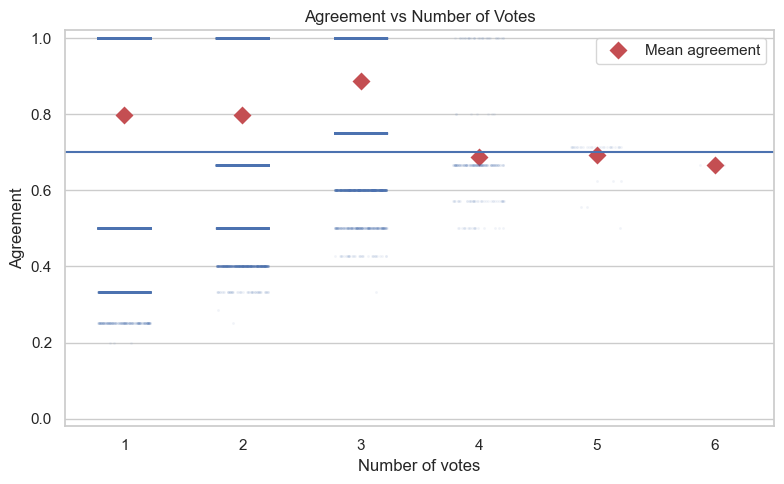

In [6]:
plot_data = results[[NUM_VOTES_COL, AGREEMENT_COL]].dropna().copy()
vote_values = [int(value) for value in sorted(plot_data[NUM_VOTES_COL].astype(int).unique())]
agreement_by_votes = (
    plot_data.groupby(NUM_VOTES_COL, as_index=False)[AGREEMENT_COL]
    .mean()
    .rename(columns={AGREEMENT_COL: "mean_agreement"})
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.stripplot(
    data=plot_data,
    x=NUM_VOTES_COL,
    y=AGREEMENT_COL,
    order=vote_values,
    jitter=0.22,
    alpha=0.08,
    size=2,
    color="C0",
    ax=ax,
)
sns.pointplot(
    data=agreement_by_votes,
    x=NUM_VOTES_COL,
    y="mean_agreement",
    order=vote_values,
    color="C3",
    errorbar=None,
    markers="D",
    linestyles="none",
    label="Mean agreement",
    ax=ax,
)

plt.axhline(0.7)
ax.set_title("Agreement vs Number of Votes")
ax.set_xlabel("Number of votes")
ax.set_ylabel("Agreement")
ax.set_ylim(-0.02, 1.02)
ax.set_xticks(range(len(vote_values)))
ax.set_xticklabels(vote_values)
ax.legend()

plt.tight_layout()

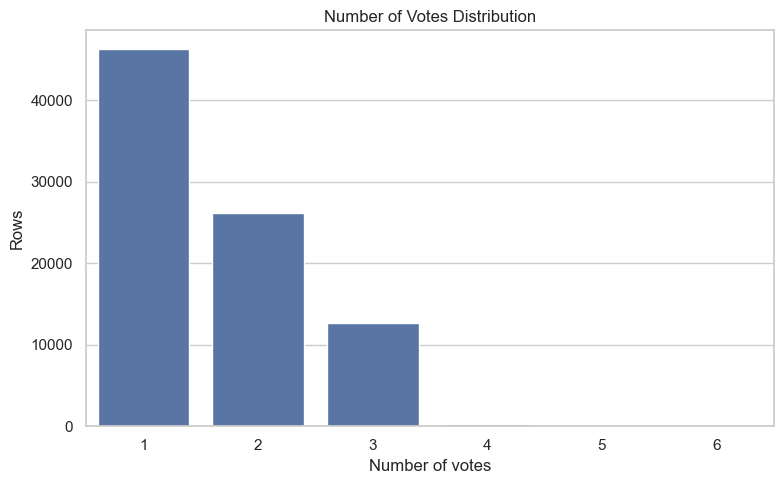

In [7]:
vote_values = [int(value) for value in sorted(results[NUM_VOTES_COL].dropna().astype(int).unique())]

fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(
    data=results.dropna(subset=[NUM_VOTES_COL]),
    x=NUM_VOTES_COL,
    order=vote_values,
    color="C0",
    ax=ax,
)

ax.set_title("Number of Votes Distribution")
ax.set_xlabel("Number of votes")
ax.set_ylabel("Rows")

plt.tight_layout()

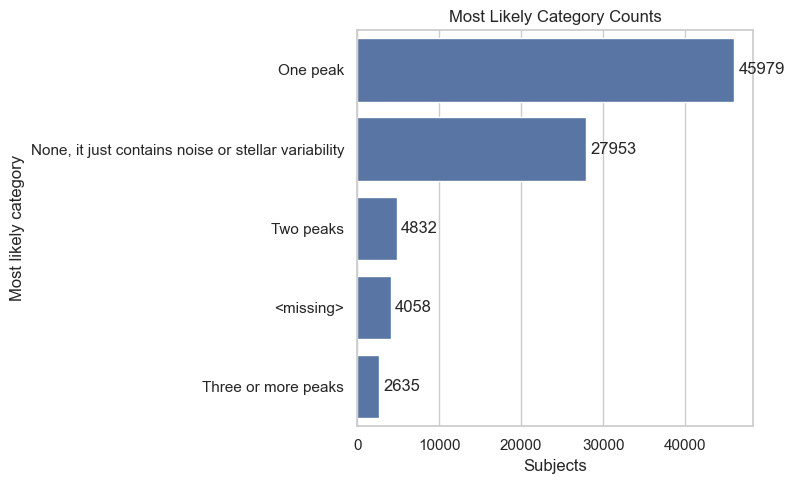

In [8]:
MOST_LIKELY_LABELS = {
    0: "None, it just contains noise or stellar variability",
    1: "One peak",
    2: "Two peaks",
    3: "Three or more peaks",
}

most_likely_counts = results[[MOST_LIKELY_COL]].copy()
most_likely_counts["most_likely_category"] = (
    pd.to_numeric(most_likely_counts[MOST_LIKELY_COL], errors="coerce")
    .map(MOST_LIKELY_LABELS)
    .fillna("<missing>")
)
most_likely_order = most_likely_counts["most_likely_category"].value_counts().index.tolist()

fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(
    data=most_likely_counts,
    y="most_likely_category",
    order=most_likely_order,
    color="C0",
    ax=ax,
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

ax.set_title("Most Likely Category Counts")
ax.set_xlabel("Subjects")
ax.set_ylabel("Most likely category")

plt.tight_layout()